# 07 — Moderation: Do Religiosity, Science & Technology and Political Culture Change the Link?

## Purpose

In `03_correlations.ipynb` we found that respondents with more educated mothers and fathers hold **less traditional** gender-role attitudes. In this notebook we ask whether this link is the **same for everyone**, or whether it depends on three other characteristics of the respondent:

1. **Religiosity:** importance of God (Q164)
2. **Attitudes to science and technology:** `science_optimism` and `science_faith_morality` (the two sub-scales confirmed in `06_pca.ipynb`)
3. **Political culture:** `authoritarian_democracy`, `liberal_democracy`, `regime_evaluation` (built in `06_pca.ipynb`) and left–right self-placement (Q240)

As agreed in our plan, we test mother's education (Q277R) and father's education (Q278R) **in separate models**, to match hypotheses H1a and H1b. That gives 7 moderators × 2 parents = **14 moderation tests**. Because mother's and father's education are strongly correlated (ρ = .687), a "mother" interaction could partly reflect the father's education (and vice versa). Section 8 therefore also fits models with **both parents' interactions together**, and checks the results with parental education entered as **categories**, with the authoritarian index **without Q247**, and at the **extremes** of each moderator.

### Hypotheses (for each parent and each moderator)

**H0:** The association between parental education and traditional gender-role attitudes does **not** depend on the moderator (interaction coefficient = 0).

**H1:** The association between parental education and traditional gender-role attitudes **does** depend on the moderator (interaction coefficient ≠ 0).

All tests are two-tailed.

## 1. What Is an Interaction (Moderation)?

So far, our models have assumed that parental education has the **same** association with gender-role attitudes for everyone. A **moderator** is a variable that changes the strength or direction of this association. For example, the link between mother's education and gender-role attitudes might be strong for less religious respondents but weak for very religious respondents, perhaps because religious teachings about gender roles "override" what they learned from an educated mother.

We test this by adding an **interaction term** to the regression, as we did with `ba_binary:sex_woman` in Week 6:

**Attitudes = b0 + b1 × ParentEdu + b2 × Moderator + b3 × (ParentEdu × Moderator)**

- **b1** is the association between parental education and attitudes **when the moderator is at its average** (because we centre the variables, see below).
- **b2** is the association between the moderator and attitudes when parental education is at its average.
- **b3**, the **interaction coefficient**, is the key number. It tells us how much the slope of parental education **changes for each one-point increase in the moderator**. If b3 = 0, the moderator makes no difference to the link. If b3 is significant, we have evidence of moderation.

Because higher gender-role scores mean **more traditional** attitudes, and parental education has a **negative** slope (b1 < 0):

- a **positive b3** means the negative slope gets **weaker** (closer to zero) as the moderator increases. Parental education matters *less* for people high on the moderator.
- a **negative b3** means the negative slope gets **stronger** (more negative) as the moderator increases. Parental education matters *more* for people high on the moderator.

### Why we centre the variables first

**Centring** means subtracting the mean from each variable, so that 0 now stands for "average". We centre all continuous predictors and moderators because:

1. **Interpretation:** without centring, b1 would be the parental education slope when the moderator equals **0**. For many of our moderators 0 is not even a possible value (the scales run from 1 to 10), so b1 would be meaningless. After centring, b1 is the slope for a respondent with an **average** score on the moderator.
2. **Less overlap between terms:** the interaction term (ParentEdu × Moderator) is usually strongly correlated with its two components when the variables are not centred. Centring reduces this overlap, which makes the estimates of b1 and b2 more stable. Centring does **not** change b3, its p-value or the model's R².

### How we treat parental education

Q277R and Q278R have three ordered levels (1 = Lower, 2 = Middle, 3 = Higher). As agreed, we treat them as **numeric scores** (centred), so b1 is the change in attitudes for moving up **one education level**. This assumes that the step from Lower to Middle has the same association as the step from Middle to Higher, and in an interaction model it also assumes that the moderator changes both steps by the same amount. This is a strong assumption: the group means in `03_correlations.ipynb` (2.167 → 2.054 → 1.837 for mothers) show that the second step is about twice as large as the first. We keep the numeric coding for the main analysis because it gives one interaction coefficient per model, which is easy to interpret, but in Section 8.1 we re-run every model with parental education entered as **categories** to check whether the conclusions depend on this assumption.

## 2. Setup and Data Loading

We use the same packages as in Weeks 5 and 6: `statsmodels` for OLS regression, `anova_lm` for F-tests comparing nested models, `Stargazer` for regression tables and `plotnine` for figures. We also use `scipy.stats` to calculate p-values for the simple slopes in Section 7.

In [1]:
from pathlib import Path  # used to build file paths that work on any computer

import pandas as pd  # data management (DataFrames)
import numpy as np  # numerical tools
from plotnine import *  # ggplot-style figures, as used in class
import warnings  # lets us silence routine warnings
warnings.filterwarnings('ignore')  # hide warnings so the output is easier to read
import statsmodels.formula.api as smf  # OLS regression with formulas, as in class
from statsmodels.stats.anova import anova_lm  # F-test for comparing nested models (Week 5)
from stargazer.stargazer import Stargazer  # regression tables (Weeks 5 and 6)
from scipy import stats  # t-distribution, used for the simple-slope p-values

In [2]:
# Identify the root folder of the GitHub repository.
PROJECT_ROOT = Path.cwd()  # start from the folder the notebook is running in
if PROJECT_ROOT.name == "code":  # if we are inside the /code folder...
    PROJECT_ROOT = PROJECT_ROOT.parent  # ...move up one level to the repository root

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "WVS_Singapore_full_cleaned.csv"  # cleaned dataset (notebooks 04-06)
OUTPUT_FIGURES = PROJECT_ROOT / "output" / "figures"  # folder for saved figures
OUTPUT_TABLES = PROJECT_ROOT / "output" / "tables"  # folder for saved tables

df = pd.read_csv(DATA_PATH)  # load the cleaned dataset
print(f"Number of respondents: {df.shape[0]}")  # number of rows

Number of respondents: 2012


## 3. Centring the Variables

We centre parental education and all seven moderators by subtracting the mean of each variable (calculated on all respondents with a valid answer). The centred versions end in `_c`. The outcome is **not** centred, so predicted values stay on the original 1–4 scale.

In [3]:
outcome = "traditional_gender_attitudes"  # the outcome: higher = more traditional (1-4)
parents = {"Q277R": "Mother's education", "Q278R": "Father's education"}  # the two parental education variables
moderators = {  # the seven moderators and readable names
    "Q164": "Religiosity (importance of God)",
    "science_optimism": "Science optimism",
    "science_faith_morality": "Science & faith/morality",
    "authoritarian_democracy": "Authoritarian notions of democracy",
    "liberal_democracy": "Liberal notions of democracy",
    "regime_evaluation": "Regime evaluation",
    "Q240": "Left-right self-placement",
}

for var in list(parents) + list(moderators):  # loop over every variable to be centred
    df[f"{var}_c"] = df[var] - df[var].mean()  # subtract the mean, so 0 = average

centring_check = pd.DataFrame({  # check the centring
    "Original mean": [df[v].mean() for v in list(parents) + list(moderators)],  # mean before centring
    "Centred mean": [df[f"{v}_c"].mean() for v in list(parents) + list(moderators)],  # should be 0
    "SD": [df[v].std() for v in list(parents) + list(moderators)],  # SD (unchanged by centring)
}, index=list(parents) + list(moderators))
centring_check.round(3)  # display the table

,Original mean,Centred mean,SD
Q277R,1.403,0.0,0.655
Q278R,1.536,-0.0,0.729
Q164,6.725,0.0,2.964
science_optimism,7.096,0.0,1.558
science_faith_morality,5.320,-0.0,2.000
authoritarian_democracy,4.361,0.0,1.745
liberal_democracy,7.649,-0.0,1.833
regime_evaluation,6.735,0.0,1.697
Q240,5.077,0.0,2.019


The centred variables all have a mean of 0, while their standard deviations are unchanged. For example, a respondent with a centred religiosity score of +2.96 is one standard deviation above the average importance of God.

## 4. A Worked Example: Religiosity × Mother's Education

To show each step, we first go through one moderator in full. We fit two models on the **same respondents**:

- **Main-effects model:** mother's education + religiosity
- **Interaction model:** mother's education + religiosity + mother's education × religiosity

In the formula, `a * b` is shorthand for `a + b + a:b`, so it includes both main effects and the interaction, just like `ba_binary + sex_woman + ba_binary:sex_woman` in Week 6.

In [4]:
example = df.dropna(subset=["Q277R", "Q164", outcome])  # respondents with valid data on all three variables

example_main = smf.ols(f"{outcome} ~ Q277R_c + Q164_c", data=example).fit()  # main-effects model
example_int = smf.ols(f"{outcome} ~ Q277R_c * Q164_c", data=example).fit()  # interaction model
print(example_int.summary())  # full regression output for the interaction model

                                 OLS Regression Results                                 
Dep. Variable:     traditional_gender_attitudes   R-squared:                       0.044
Model:                                      OLS   Adj. R-squared:                  0.042
Method:                           Least Squares   F-statistic:                     27.89
Date:                          Mon, 02 Nov 2026   Prob (F-statistic):           1.24e-17
Time:                                  01:20:27   Log-Likelihood:                -1493.9
No. Observations:                          1842   AIC:                             2996.
Df Residuals:                              1838   BIC:                             3018.
Df Model:                                     3                                         
Covariance Type:                      nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
---------------------------

In [5]:
print(anova_lm(example_main, example_int))  # F-test: does adding the interaction improve the model?

   df_resid         ssr  df_diff   ss_diff         F    Pr(>F)
0    1839.0  546.834319      0.0       NaN       NaN       NaN
1    1838.0  546.092864      1.0  0.741455  2.495536  0.114342


### Interpretation

The interaction model is based on **N = 1,842** respondents and explains **4.4%** of the variance in traditional gender-role attitudes (R² = .044).

- **Intercept = 2.1145:** the predicted gender-role score for a respondent whose mother's education and religiosity are both at the sample average.
- **Mother's education (b1 = −0.1351, p < .001):** for a respondent with average religiosity, each step up in mother's education level (e.g. from Lower to Middle) is associated with a gender-role score that is **0.135 points lower**, meaning less traditional.
- **Religiosity (b2 = 0.0194, p < .001):** for a respondent whose mother has average education, each extra point on the 1–10 importance-of-God scale is associated with a **0.019-point higher** (more traditional) score. Over the full range of the scale (9 points), this adds up to about 0.17 points.
- **Interaction (b3 = 0.0098, p = .114):** the interaction is **positive but not statistically significant**. Taken at face value, the slope of mother's education would become slightly weaker (less negative) as religiosity increases, but the 95% confidence interval (−0.002 to 0.022) includes zero.

The F-test gives the same answer: adding the interaction does **not** significantly improve the model (**F = 2.50, p = .114**). This is the same test as the t-test for b3, because we are only adding one term.

We therefore **do not reject H0** for this moderator. We have no evidence that religiosity changes the association between mother's education and gender-role attitudes. Religiosity and mother's education each have their own association with attitudes, and the two associations simply add up.

## 5. Fitting All Moderation Models

We now repeat the same steps for every combination of parent and moderator. To avoid copying the same code 14 times, we write a function that:

1. keeps respondents with valid data on the parent, the moderator and the outcome,
2. fits the main-effects model and the interaction model on these same respondents,
3. runs the F-test comparing them, and
4. returns the key results in one row.

In [6]:
def fit_moderation(parent, moderator):
    # Fit the main-effects and interaction models for one parent and one moderator, and return the key results.
    data = df.dropna(subset=[parent, moderator, outcome])  # same respondents for both models
    main = smf.ols(f"{outcome} ~ {parent}_c + {moderator}_c", data=data).fit()  # main-effects model
    inter = smf.ols(f"{outcome} ~ {parent}_c * {moderator}_c", data=data).fit()  # interaction model
    f_test = anova_lm(main, inter)  # F-test comparing the two models
    term = f"{parent}_c:{moderator}_c"  # name of the interaction term in the output
    row = {
        "Parent": parents[parent], "Moderator": moderators[moderator], "N": int(inter.nobs),  # labels and sample size
        "b1 parent (at mean moderator)": inter.params[f"{parent}_c"],  # slope of parental education
        "p b1": inter.pvalues[f"{parent}_c"],  # its p-value
        "b2 moderator": inter.params[f"{moderator}_c"],  # slope of the moderator
        "p b2": inter.pvalues[f"{moderator}_c"],  # its p-value
        "b3 interaction": inter.params[term],  # interaction coefficient
        "SE b3": inter.bse[term],  # its standard error
        "p b3": inter.pvalues[term],  # its p-value
        "R2 main": main.rsquared, "R2 interaction": inter.rsquared,  # R-squared of both models
        "Change in R2": inter.rsquared - main.rsquared,  # extra variance explained by the interaction
        "F-test p": f_test["Pr(>F)"].iloc[1],  # p-value of the F-test
    }
    return main, inter, row  # return both models and the summary row


models = {}  # dictionary to store the interaction models, so we can use them for the simple slopes
rows = []  # list to collect one results row per model
for parent in parents:  # loop over mother's and father's education
    for moderator in moderators:  # loop over the seven moderators
        main, inter, row = fit_moderation(parent, moderator)  # fit the two models
        models[(parent, moderator)] = inter  # store the interaction model
        rows.append(row)  # store the results row

results = pd.DataFrame(rows)  # combine all rows into one table
results.to_csv(OUTPUT_TABLES / "moderation_results.csv", index=False)  # save the full results table
print(f"Number of moderation models fitted: {len(results)}")  # confirm that all 14 models were fitted

Number of moderation models fitted: 14


To make the regression tables easier to read, we also write a small function that prints a Stargazer table for one moderator (mother's and father's models side by side), with readable variable names.

In [7]:
def moderation_table(moderator):
    # Show a Stargazer table with the mother and father interaction models for one moderator.
    m_model, f_model = models[("Q277R", moderator)], models[("Q278R", moderator)]  # the two interaction models
    sg = Stargazer([m_model, f_model])  # create the table
    sg.title(f"Moderation by {moderators[moderator]}")  # title
    sg.dependent_variable_name("Traditional gender-role attitudes")  # name of the outcome
    sg.custom_columns(["Mother's education", "Father's education"], [1, 1])  # column labels
    sg.rename_covariates({  # readable names for the coefficients
        "Q277R_c": "Mother's education (centred)", "Q278R_c": "Father's education (centred)",
        f"{moderator}_c": f"{moderators[moderator]} (centred)",
        f"Q277R_c:{moderator}_c": "Mother's education × moderator",
        f"Q278R_c:{moderator}_c": "Father's education × moderator",
        "Intercept": "Intercept"})
    return sg  # return the table so it is displayed


def show_rows(moderator_list):
    # Display the summary rows for a list of moderators.
    names = [moderators[m] for m in moderator_list]  # readable names of the moderators
    cols = ["Parent", "Moderator", "N", "b1 parent (at mean moderator)", "p b1", "b2 moderator", "p b2",
            "b3 interaction", "p b3", "Change in R2"]  # columns to show
    return results.loc[results["Moderator"].isin(names), cols].round(4)  # rows for these moderators, rounded

## 6. Results by Moderator

### 6.1 Moderator 1: Religiosity (Q164)

In [8]:
moderation_table("Q164")  # regression table for religiosity

In [9]:
show_rows(["Q164"])  # key numbers for religiosity

,Parent,Moderator,N,b1 parent (at mean moderator),p b1,b2 moderator,p b2,b3 interaction,p b3,Change in R2
0,Mother's education,Religiosity (importance of God),1842,-0.1351,0.0,0.0194,0.0,0.0098,0.1143,0.0013
7,Father's education,Religiosity (importance of God),1782,-0.1231,0.0,0.0222,0.0,0.0085,0.1346,0.0012


### Interpretation

For **both parents**, religiosity is associated with more traditional gender-role attitudes on its own (b2 = **0.019** for the mother's model and **0.022** for the father's model, both p < .001), and parental education is associated with less traditional attitudes (b1 = **−0.135** and **−0.123**, both p < .001).

However, the interaction terms are **small and not significant**:

- **Mother's education × religiosity:** b3 = 0.0098, **p = .114**
- **Father's education × religiosity:** b3 = 0.0085, **p = .135**

Adding the interaction increases R² by only **0.13%** and **0.12%**.

**Conclusion:** we **do not reject H0** for religiosity. The link between parental education and gender-role attitudes appears to be about the same for more and less religious respondents. Religiosity matters for gender-role attitudes, but it acts as a separate influence rather than one that changes the effect of parental education.

### 6.2 Moderator 2: Attitudes to Science and Technology

We test the two science sub-scales separately, because `06_pca.ipynb` showed that they are different dimensions.

In [10]:
moderation_table("science_optimism")  # regression table for science optimism

In [11]:
moderation_table("science_faith_morality")  # regression table for science and faith/morality

In [12]:
show_rows(["science_optimism", "science_faith_morality"])  # key numbers for the two science sub-scales

,Parent,Moderator,N,b1 parent (at mean moderator),p b1,b2 moderator,p b2,b3 interaction,p b3,Change in R2
1,Mother's education,Science optimism,1841,-0.1479,0.0,0.0130,0.1174,0.0271,0.0337,0.0024
2,Mother's education,Science & faith/morality,1829,-0.1250,0.0,-0.0557,0.0000,-0.0243,0.0112,0.0033
8,Father's education,Science optimism,1781,-0.1324,0.0,0.0128,0.1315,0.0238,0.0374,0.0024
9,Father's education,Science & faith/morality,1772,-0.1116,0.0,-0.0578,0.0000,-0.0339,0.0001,0.0081


### Interpretation

**Science optimism.** On its own, science optimism is **not** significantly associated with gender-role attitudes (b2 = 0.013, p = .117 for the mother's model and p = .132 for the father's model). However, there is a **positive interaction** for both parents:

- **Mother:** b3 = 0.0271, **p = .034**
- **Father:** b3 = 0.0238, **p = .037**

A positive b3 means that the negative slope of parental education becomes **weaker** among respondents who are more optimistic about science. Parental education makes more of a difference for respondents who are *less* optimistic about science.

**Science and faith/morality.** Respondents who are less concerned that science undermines faith and morality hold **less traditional** attitudes (b2 = −0.056 and −0.058, both p < .001). There is a **negative interaction** for both parents:

- **Mother:** b3 = −0.0243, **p = .011**
- **Father:** b3 = −0.0339, **p < .001**

A negative b3 means that the negative slope of parental education becomes **stronger** among respondents who are *less* worried about science's moral effects. Put the other way round: among respondents who believe science threatens faith and morality, parental education is less strongly linked to their gender-role attitudes.

**Conclusion:** for both sub-scales, we **reject H0** at the .05 level. The father × faith/morality interaction is the strongest of the science results (ΔR² = **0.81%**). The effects of science optimism are weaker and only just significant (ΔR² = 0.24% for both parents). As we explain in Section 6.4, the science optimism results do not survive a correction for multiple testing.

### 6.3 Moderator 3: Political Culture

We test the four political culture measures from `06_pca.ipynb` one at a time.

In [13]:
moderation_table("authoritarian_democracy")  # regression table for authoritarian notions of democracy

In [14]:
moderation_table("liberal_democracy")  # regression table for liberal notions of democracy

In [15]:
moderation_table("regime_evaluation")  # regression table for regime evaluation

In [16]:
moderation_table("Q240")  # regression table for left-right self-placement

In [17]:
show_rows(["authoritarian_democracy", "liberal_democracy", "regime_evaluation", "Q240"])  # key numbers for political culture

,Parent,Moderator,N,b1 parent (at mean moderator),p b1,b2 moderator,p b2,b3 interaction,p b3,Change in R2
3,Mother's education,Authoritarian notions of democracy,1703,-0.1135,0.0,0.0941,0.0000,0.0356,0.0022,0.0048
4,Mother's education,Liberal notions of democracy,1743,-0.1457,0.0,-0.0320,0.0000,-0.0437,0.0001,0.0085
5,Mother's education,Regime evaluation,1802,-0.1413,0.0,0.0178,0.0195,0.0332,0.0059,0.0041
6,Mother's education,Left-right self-placement,1619,-0.1106,0.0,0.0318,0.0000,0.0191,0.0663,0.0020
10,Father's education,Authoritarian notions of democracy,1650,-0.1083,0.0,0.0950,0.0000,0.0217,0.0327,0.0024
11,Father's education,Liberal notions of democracy,1686,-0.1290,0.0,-0.0302,0.0000,-0.0289,0.0038,0.0048
12,Father's education,Regime evaluation,1743,-0.1266,0.0,0.0175,0.0244,0.0336,0.0016,0.0055
13,Father's education,Left-right self-placement,1568,-0.1033,0.0,0.0305,0.0000,0.0232,0.0096,0.0041


### Interpretation

All four political culture measures are associated with gender-role attitudes on their own (all b2 p < .05). Respondents who see **authoritarian** features as more essential to democracy are clearly **more traditional** (b2 ≈ **0.094**, p < .001). Those who see **liberal** features as essential are less traditional (b2 ≈ −0.03, p < .001). Respondents who are further to the **right** (b2 ≈ 0.03, p < .001) and those who **evaluate the regime more positively** (b2 ≈ 0.018, p < .05) are slightly more traditional.

The interactions are significant for most political measures:

| Moderator | Mother: b3 (p) | Father: b3 (p) | Direction |
|---|---|---|---|
| Authoritarian notions | **0.0356 (p = .002)** | 0.0217 (p = .033) | Parental education matters **less** for more authoritarian respondents |
| Liberal notions | **−0.0437 (p < .001)** | −0.0289 (p = .004) | Parental education matters **more** for more liberal respondents |
| Regime evaluation | 0.0332 (p = .006) | **0.0336 (p = .002)** | Parental education matters **less** for respondents more satisfied with the regime |
| Left–right | 0.0191 (p = .066) | 0.0232 (p = .010) | Parental education matters **less** for right-leaning respondents (only significant for fathers) |

**Conclusion:** we **reject H0** for authoritarian notions, liberal notions and regime evaluation, for both parents, and for left–right placement for fathers only. For mothers, the left–right interaction is not significant (p = .066). The strongest interaction is **mother's education × liberal notions of democracy** (b3 = −0.0437, ΔR² = **0.85%**). The pattern is consistent: the association between parental education and less traditional gender-role attitudes is **strongest for respondents who hold liberal, less authoritarian political views**, and **weakest for those who hold authoritarian views, are on the right, or are very satisfied with the current political system**.

### 6.4 All Results Together, and the Problem of Multiple Tests

We ran **14** interaction tests. If we use p < .05 for each one, the chance of getting at least one "significant" result purely by chance is much higher than 5%. A simple and conservative way to deal with this is the **Bonferroni correction**: we divide .05 by the number of tests, giving a stricter threshold of **.05 / 14 ≈ .0036**. Below we flag which interactions pass the usual .05 threshold and which also pass the stricter Bonferroni threshold.

In [18]:
bonferroni = 0.05 / len(results)  # Bonferroni-corrected threshold
summary = results[["Parent", "Moderator", "N", "b3 interaction", "SE b3", "p b3", "Change in R2"]].copy()  # key columns
summary["p < .05"] = np.where(summary["p b3"] < 0.05, "Yes", "No")  # significant at the usual level?
summary["p < Bonferroni"] = np.where(summary["p b3"] < bonferroni, "Yes", "No")  # significant after the correction?

print(f"Bonferroni threshold = {bonferroni:.4f}")  # print the threshold
summary.to_csv(OUTPUT_TABLES / "moderation_summary.csv", index=False)  # save the summary table
summary.round(4)  # display the table

Bonferroni threshold = 0.0036


,Parent,Moderator,N,b3 interaction,SE b3,p b3,Change in R2,p < .05,p < Bonferroni
0,Mother's education,Religiosity (importance of God),1842,0.0098,0.0062,0.1143,0.0013,No,No
1,Mother's education,Science optimism,1841,0.0271,0.0127,0.0337,0.0024,Yes,No
2,Mother's education,Science & faith/morality,1829,-0.0243,0.0096,0.0112,0.0033,Yes,No
3,Mother's education,Authoritarian notions of democracy,1703,0.0356,0.0116,0.0022,0.0048,Yes,Yes
4,Mother's education,Liberal notions of democracy,1743,-0.0437,0.0110,0.0001,0.0085,Yes,Yes
5,Mother's education,Regime evaluation,1802,0.0332,0.0120,0.0059,0.0041,Yes,No
6,Mother's education,Left-right self-placement,1619,0.0191,0.0104,0.0663,0.0020,No,No
7,Father's education,Religiosity (importance of God),1782,0.0085,0.0057,0.1346,0.0012,No,No
8,Father's education,Science optimism,1781,0.0238,0.0114,0.0374,0.0024,Yes,No
9,Father's education,Science & faith/morality,1772,-0.0339,0.0086,0.0001,0.0081,Yes,Yes


### Interpretation

Of the 14 interaction tests, **11 are significant at p < .05**. Only the two religiosity interactions and the mother × left–right interaction are not.

After the stricter Bonferroni correction (p < .0036), **four interactions remain significant**:

1. **Mother's education × liberal notions of democracy** (b3 = −0.0437, p = .0001)
2. **Father's education × science & faith/morality** (b3 = −0.0339, p = .0001)
3. **Father's education × regime evaluation** (b3 = 0.0336, p = .0016)
4. **Mother's education × authoritarian notions of democracy** (b3 = 0.0356, p = .0022)

Father × liberal notions (p = .0038) narrowly misses the corrected threshold. The interactions for science optimism (p ≈ .034–.037) and the father's interaction with authoritarian notions (p = .033) are the least robust, and could be chance findings.

**How large are these effects?** All the interactions are **small**. Adding an interaction term increases R² by between **0.12% and 0.85%**. In other words, the moderators change the *strength* of the parental education association in a consistent way, but they explain very little extra variation in gender-role attitudes. Even so, interaction effects in survey data are usually small, and a consistent pattern across many moderators is more convincing than any single result. We discuss this pattern below.

## 7. Simple Slopes

A significant interaction coefficient tells us *that* the slope of parental education changes with the moderator, but not what the slope actually is for different groups of people. To make this concrete, we calculate **simple slopes**: the slope of parental education for respondents who are **low** (1 SD below the mean), **average**, and **high** (1 SD above the mean) on the moderator.

We did not calculate simple slopes in class, so we explain the method here. Since the moderator is centred, the slope of parental education at a given moderator value *m* is:

**slope = b1 + b3 × m**

Its standard error comes from the variances and covariance of b1 and b3 (taken from `model.cov_params()`), and the p-value comes from the t-distribution, in the same way `statsmodels` calculates the p-values in its summary tables.

In [19]:
def simple_slopes(parent, moderator):
    # Calculate the slope of parental education at low (-1 SD), average and high (+1 SD) values of the moderator.
    model = models[(parent, moderator)]  # the fitted interaction model
    b, V = model.params, model.cov_params()  # coefficients and their variance-covariance matrix
    p_term, i_term = f"{parent}_c", f"{parent}_c:{moderator}_c"  # names of b1 and b3
    sd = df[moderator].std()  # standard deviation of the moderator
    out = []  # list to collect the results
    for label, m in [("Low (-1 SD)", -sd), ("Average", 0.0), ("High (+1 SD)", sd)]:  # three moderator values
        slope = b[p_term] + b[i_term] * m  # simple slope: b1 + b3 * m
        se = np.sqrt(V.loc[p_term, p_term] + m ** 2 * V.loc[i_term, i_term] + 2 * m * V.loc[p_term, i_term])  # its SE
        t = slope / se  # t statistic
        p = 2 * stats.t.sf(abs(t), model.df_resid)  # two-tailed p-value
        out.append({"Parent": parents[parent], "Moderator": moderators[moderator], "Moderator level": label,
                    "Simple slope": slope, "SE": se, "p-value": p})  # store the results
    return out  # return the three rows


slopes = pd.DataFrame([row for parent in parents for moderator in moderators  # all 14 models...
                       for row in simple_slopes(parent, moderator)])  # ...times three moderator levels
slopes.to_csv(OUTPUT_TABLES / "moderation_simple_slopes.csv", index=False)  # save the table
slopes.pivot_table(index=["Parent", "Moderator"], columns="Moderator level", values="Simple slope",  # wide format:
                   sort=False)[["Low (-1 SD)", "Average", "High (+1 SD)"]].round(3)  # one row per model

Moderator level                                        Low (-1 SD)  Average  \
Parent             Moderator                                                  
Mother's education Religiosity (importance of God)          -0.164   -0.135   
                   Science optimism                         -0.190   -0.148   
                   Science & faith/morality                 -0.076   -0.125   
                   Authoritarian notions of democracy       -0.176   -0.114   
                   Liberal notions of democracy             -0.066   -0.146   
                   Regime evaluation                        -0.198   -0.141   
                   Left-right self-placement                -0.149   -0.111   
Father's education Religiosity (importance of God)          -0.148   -0.123   
                   Science optimism                         -0.170   -0.132   
                   Science & faith/morality                 -0.044   -0.112   
                   Authoritarian notions of democracy       -0.146   -0.108   
                   Liberal notions of democracy             -0.076   -0.129   
                   Regime evaluation                        -0.184   -0.127   
                   Left-right self-placement                -0.150   -0.103   

Moderator level                                        High (+1 SD)  
Parent             Moderator                                         
Mother's education Religiosity (importance of God)           -0.106  
                   Science optimism                          -0.106  
                   Science & faith/morality                  -0.174  
                   Authoritarian notions of democracy        -0.051  
                   Liberal notions of democracy              -0.226  
                   Regime evaluation                         -0.085  
                   Left-right self-placement                 -0.072  
Father's education Religiosity (importance of God)           -0.098  
                   Science optimism                          -0.095  
                   Science & faith/morality                  -0.179  
                   Authoritarian notions of democracy        -0.070  
                   Liberal notions of democracy              -0.182  
                   Regime evaluation                         -0.070  
                   Left-right self-placement                 -0.056

### Interpretation

The simple slopes show how much the association between parental education and gender-role attitudes changes across the moderators. **At the three moderator values we evaluated (−1 SD, the mean and +1 SD), all the estimated parental education slopes are negative.** What changes is **how strong** this link is. We did not evaluate every possible moderator value, and for some moderators the estimated slope approaches or crosses zero at more extreme observed values (see Section 8.4).

- **Authoritarian notions (mother):** the slope is **−0.176** for respondents low on authoritarianism, but only **−0.051** for those high on it. The slope for highly authoritarian respondents is **not significant** (p = .098). Among respondents who see authoritarian features as essential to democracy, having a more educated mother is barely related to their gender-role attitudes.
- **Liberal notions (mother):** the slope is more than three times stronger for highly liberal respondents (**−0.226**) than for less liberal respondents (**−0.066**).
- **Science and faith/morality (father):** the slope is **−0.179** for respondents who are not worried about science undermining morality, but only **−0.044** (not significant, p = .085) for those who are worried.
- **Regime evaluation (father):** **−0.184** for respondents who are less satisfied with the political system vs. **−0.070** for those who are more satisfied.
- **Religiosity:** the slopes change only a little (from −0.164 to −0.106 for mothers), and since the interaction was not significant, this small change could be due to chance.

All slope p-values are available in `output/tables/moderation_simple_slopes.csv`.

### 7.1 Simple-Slopes Plots

We now plot the **predicted** gender-role score at each level of parental education (Lower, Middle, Higher) for respondents who are low, average or high on each moderator. We use `model.predict()` with a small table of chosen values, the same idea as the predictions behind the marginal effects in Weeks 6 and 8.

If there is no moderation, the three lines are **parallel**. If the lines have different slopes (they fan out or come together), the association between parental education and gender-role attitudes depends on the moderator.

In [20]:
def prediction_grid(parent, moderator):
    # Predicted attitudes at each parental education level for low, average and high values of the moderator.
    model = models[(parent, moderator)]  # the fitted interaction model
    sd = df[moderator].std()  # standard deviation of the moderator
    grid = pd.DataFrame([(edu, label, m) for edu in [1, 2, 3]  # every combination of education level...
                         for label, m in [("Low (-1 SD)", -sd), ("Average", 0.0), ("High (+1 SD)", sd)]],  # ...and moderator level
                        columns=["education", "Moderator level", f"{moderator}_c"])
    grid[f"{parent}_c"] = grid["education"] - df[parent].mean()  # centre the education levels, as in the model
    grid["predicted"] = model.predict(grid)  # predicted gender-role score
    grid["Moderator"] = moderators[moderator]  # moderator name, used for the panels
    return grid  # return the table of predictions


def slopes_plot(parent):
    # Faceted simple-slopes plot for one parent across all seven moderators.
    pred = pd.concat([prediction_grid(parent, m) for m in moderators])  # predictions for every moderator
    pred["Moderator level"] = pd.Categorical(pred["Moderator level"], ["Low (-1 SD)", "Average", "High (+1 SD)"])  # order
    pred["Moderator"] = pd.Categorical(pred["Moderator"], list(moderators.values()))  # keep the panel order
    p = (
        ggplot(pred, aes("education", "predicted", color="Moderator level"))  # x = education level, y = prediction
        + geom_line(size=1)  # one line per moderator level
        + geom_point(size=2)  # points at each education level
        + facet_wrap("~Moderator", ncol=4)  # one panel per moderator
        + scale_x_continuous(breaks=[1, 2, 3], labels=["Lower", "Middle", "Higher"])  # label the education levels
        + scale_color_manual(values=["#4C78A8", "#9D9D9D", "#E45756"])  # blue = low, grey = average, red = high
        + theme_light()  # clean background
        + labs(x=parents[parent], y="Predicted traditional gender-role score",  # axis labels
               title=f"Simple slopes: {parents[parent].lower()} and traditional gender-role attitudes",  # title
               color="Moderator")  # legend title
        + theme(figure_size=(13, 6.5), legend_position="bottom")  # figure size and legend position
    )
    p.save(OUTPUT_FIGURES / f"moderation_simple_slopes_{'mother' if parent == 'Q277R' else 'father'}.png",
           dpi=300, verbose=False)  # save the figure
    return p  # return the plot so it is displayed

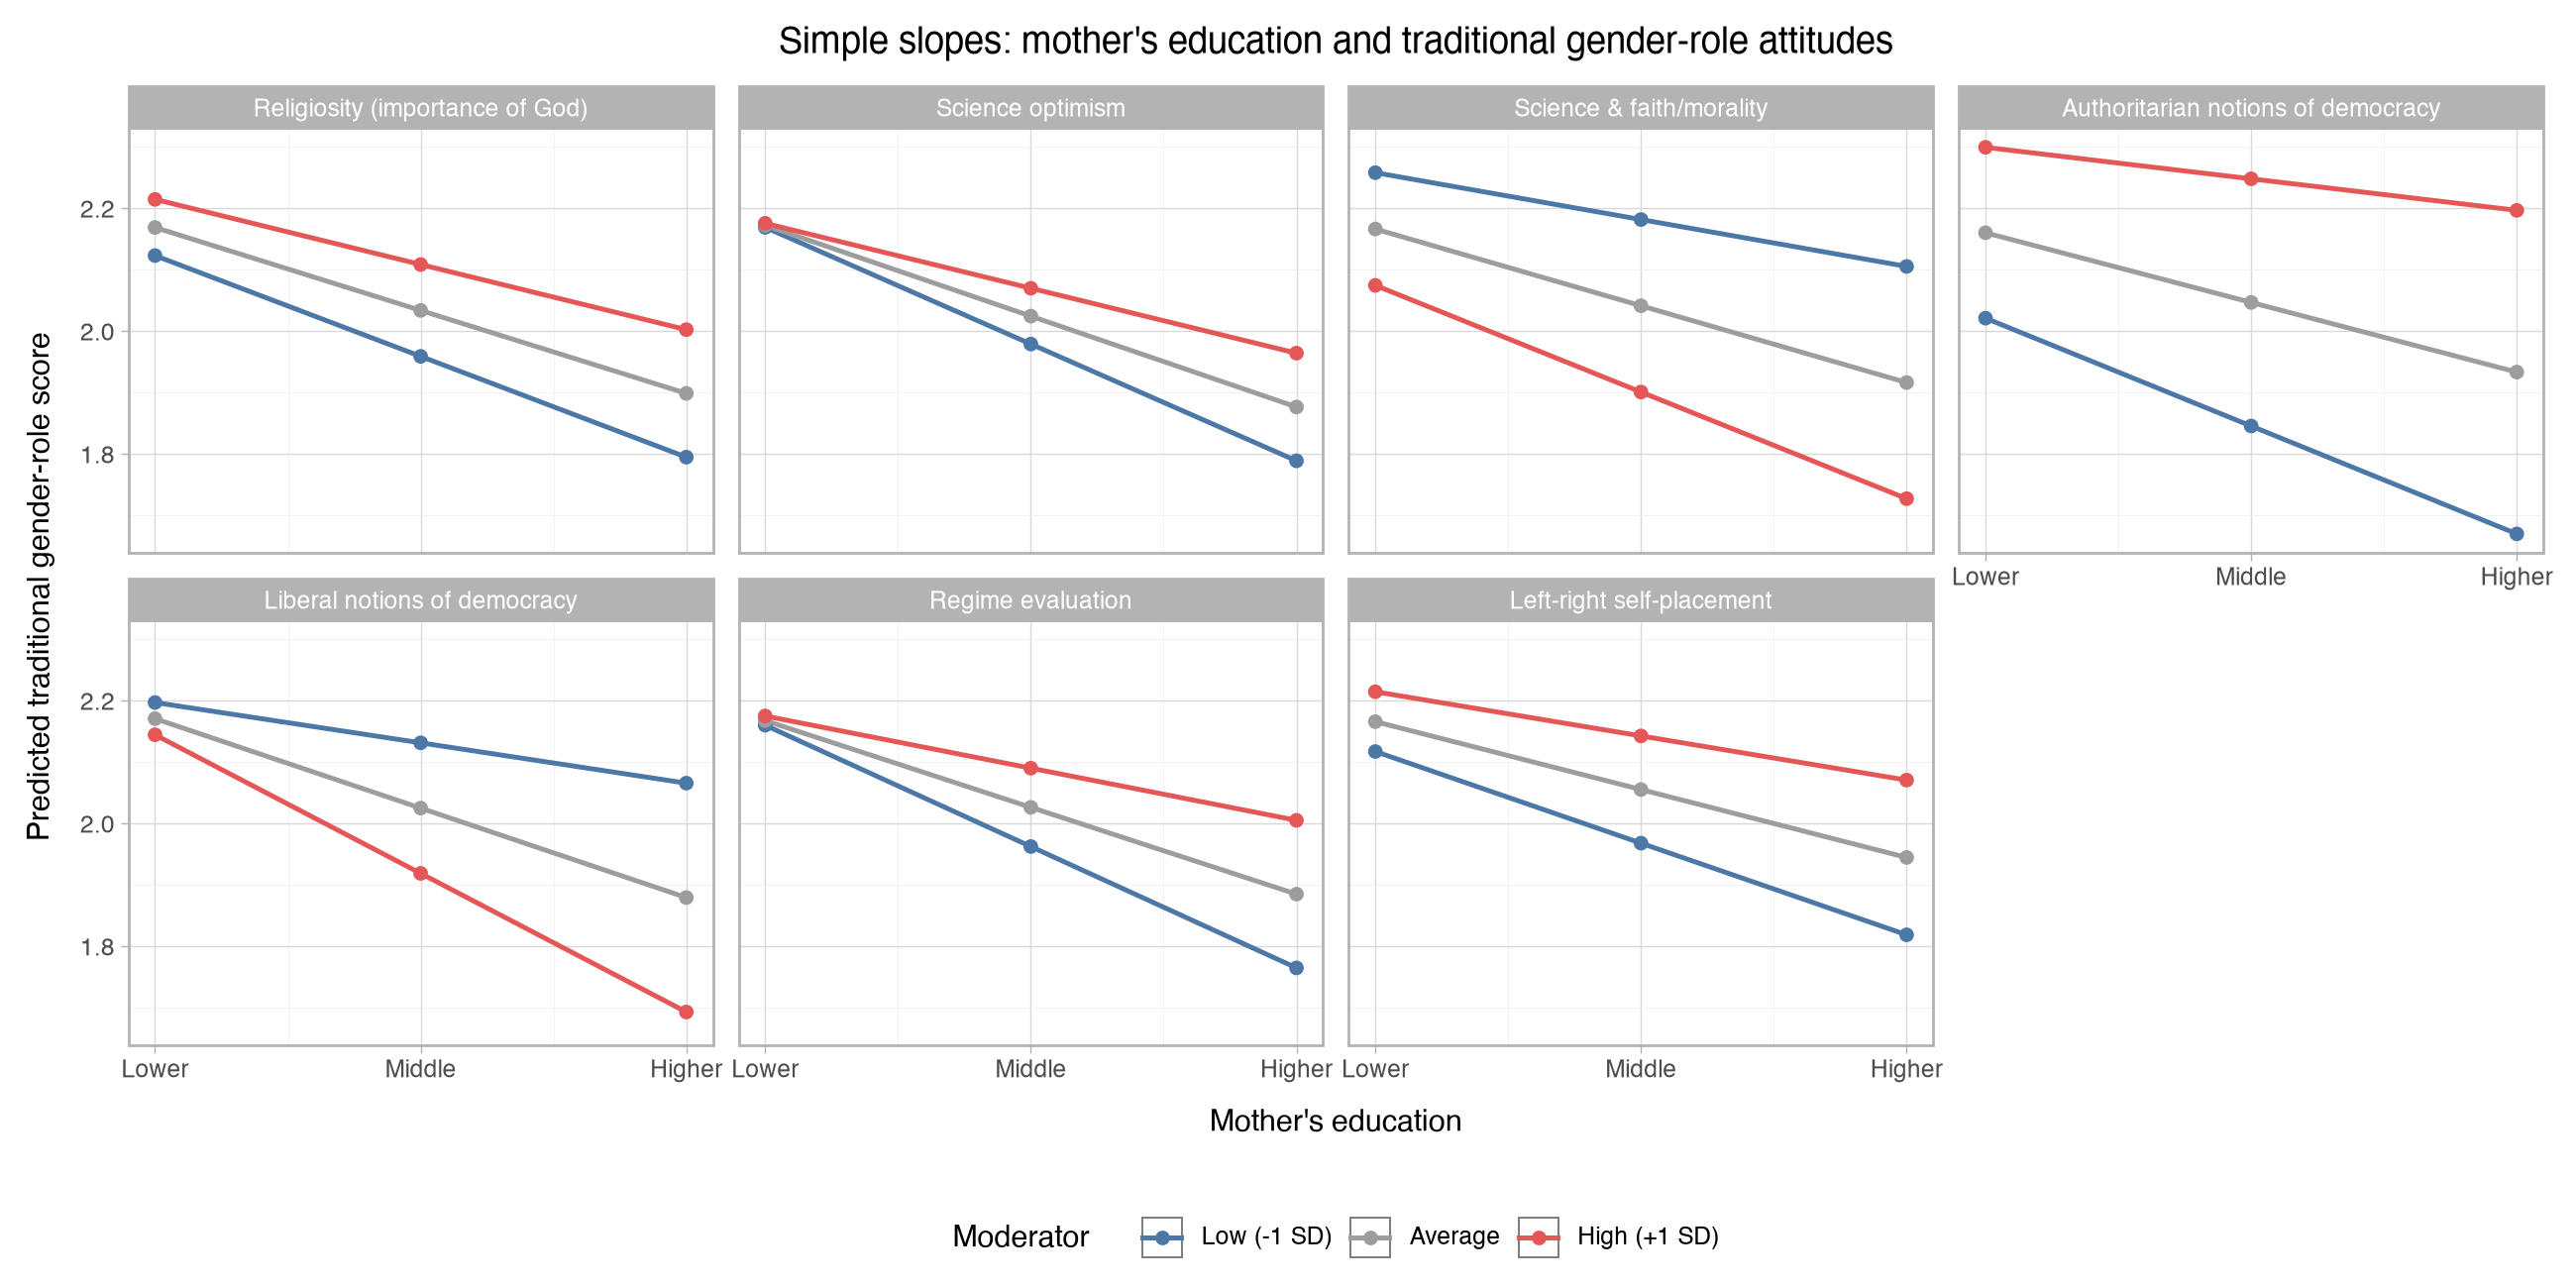

In [21]:
slopes_plot("Q277R")  # simple-slopes plot for mother's education

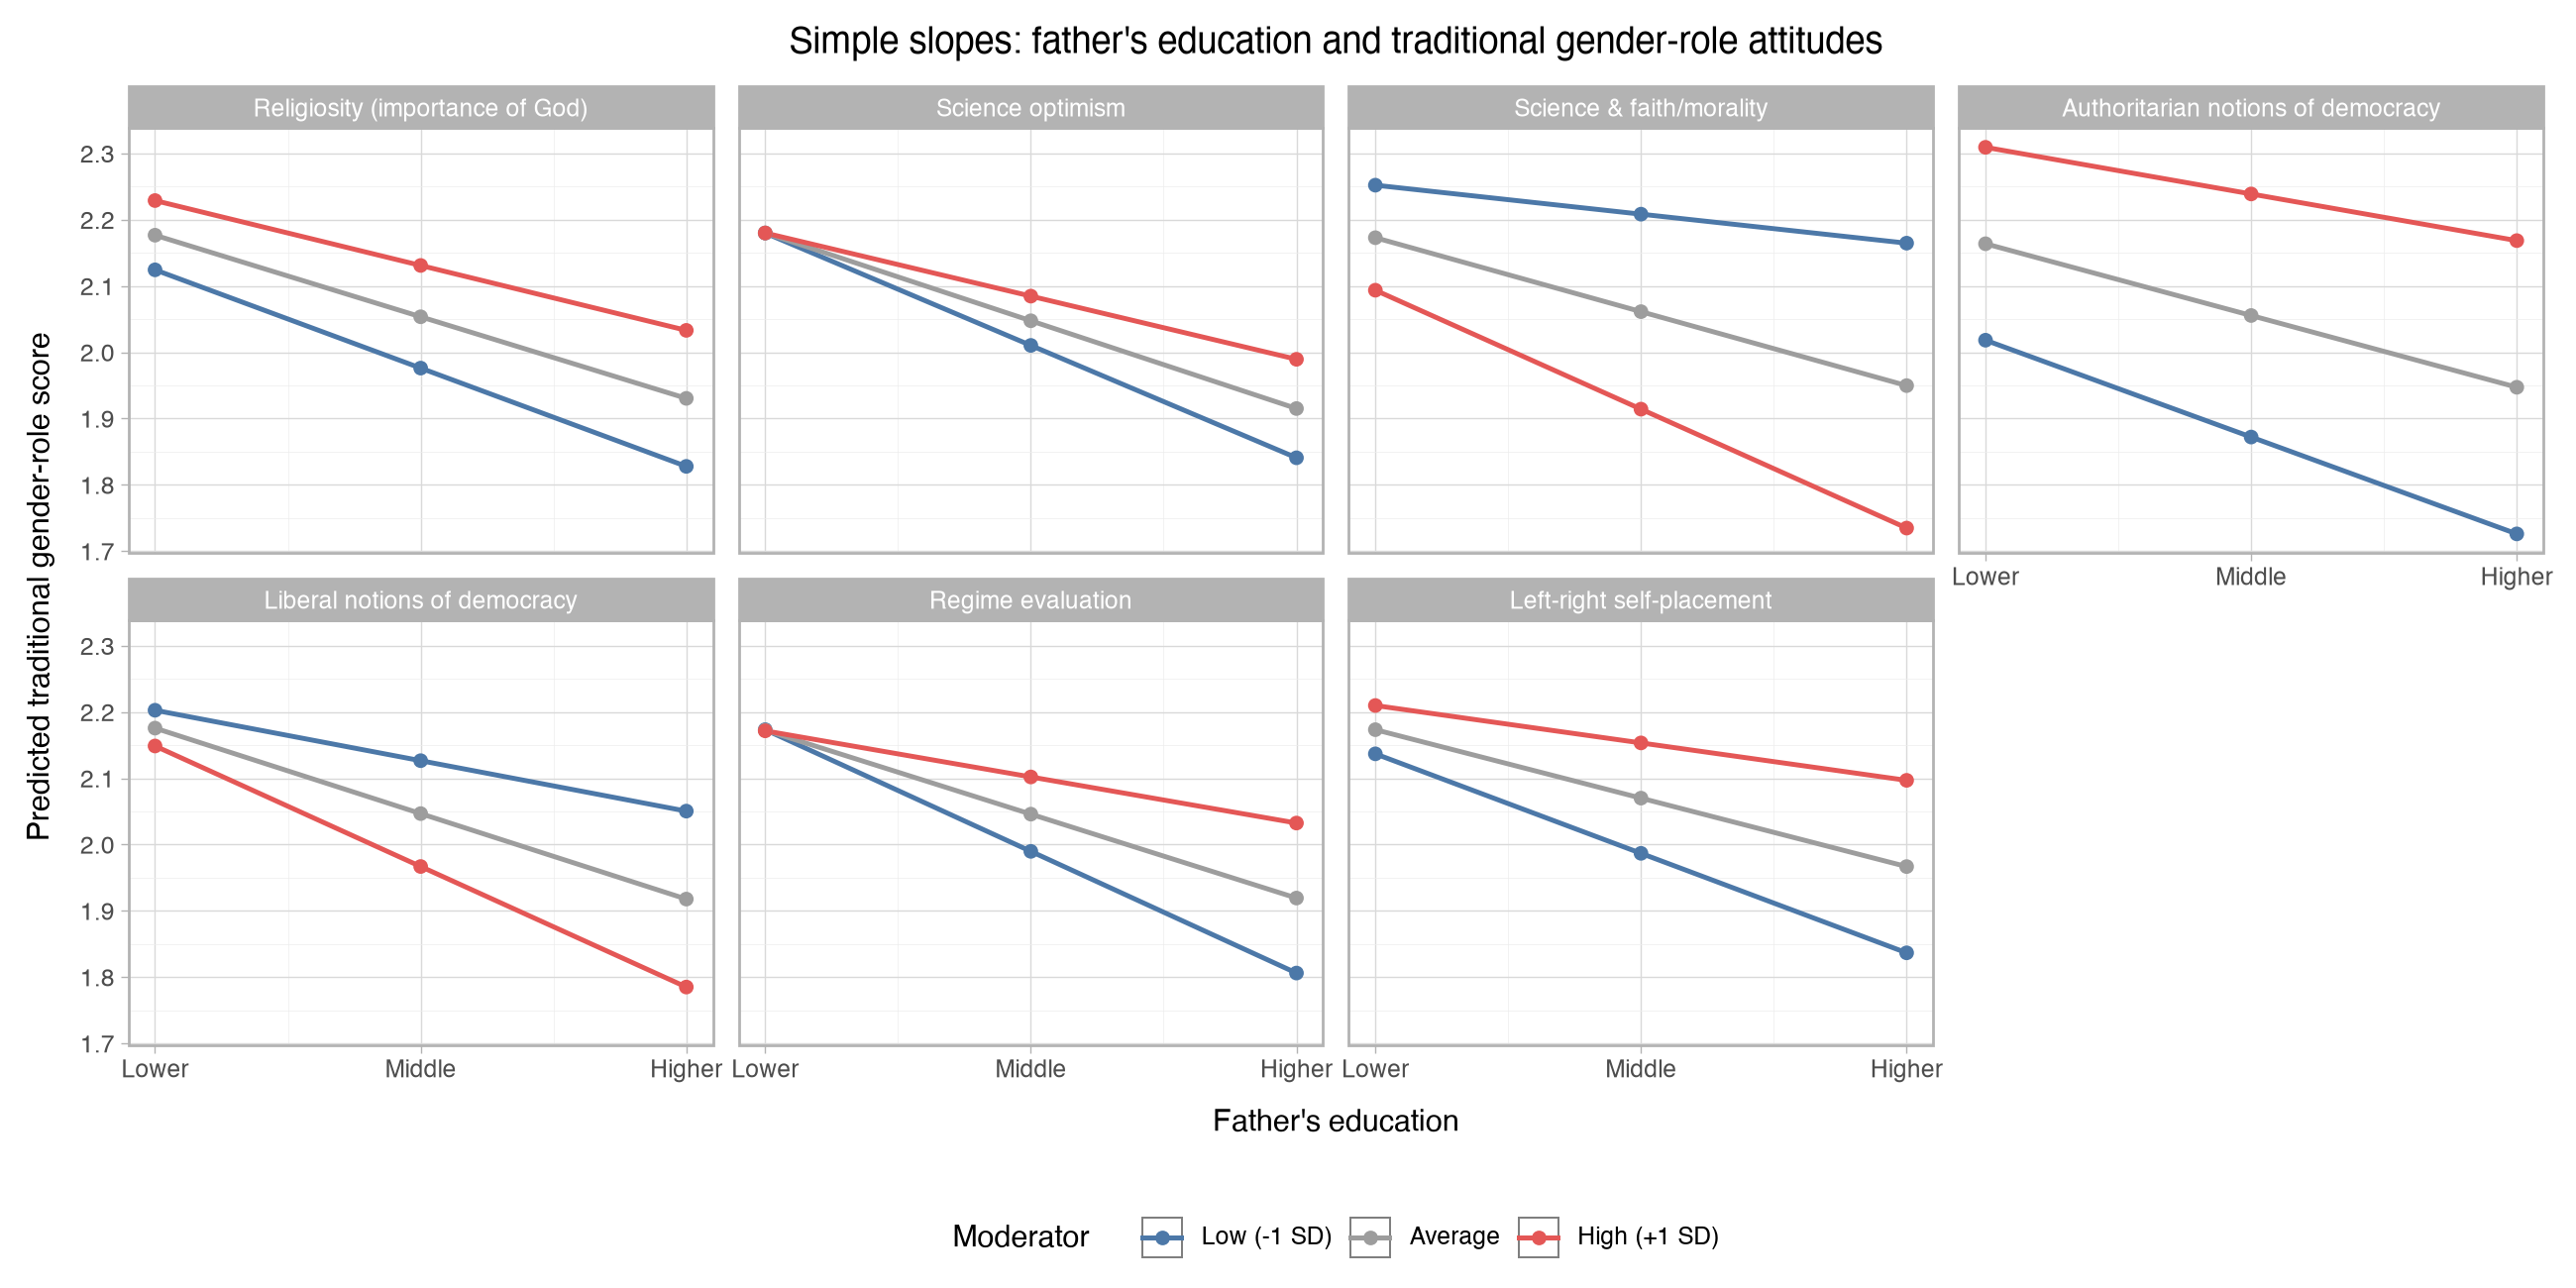

In [22]:
slopes_plot("Q278R")  # simple-slopes plot for father's education

### Interpretation

In every panel, the lines slope **downwards**: respondents whose parents are more educated are predicted to hold less traditional gender-role attitudes. The key question is whether the three lines are **parallel**.

- **Religiosity:** the three lines are close to parallel, which matches the non-significant interaction. More religious respondents (red) are more traditional at every level of parental education, but the slopes are similar.
- **Authoritarian notions of democracy:** the lines **fan out** most clearly. For respondents low on authoritarianism (blue), the predicted score drops from about **2.02 to 1.67** as mother's education goes from Lower to Higher. For highly authoritarian respondents (red), it hardly changes (about **2.30 to 2.20**). The gap between authoritarian and non-authoritarian respondents is therefore much **bigger** among those with highly educated parents.
- **Liberal notions of democracy and science & faith/morality:** the lines fan out in the opposite direction. The red line (high on the moderator) is the steepest. Respondents with less educated parents are similar regardless of their liberal or science views, but among respondents with highly educated parents, those with liberal or secular views are much less traditional.
- **Regime evaluation, science optimism and left–right placement:** the lines for low values (blue) are steeper than those for high values (red), although the differences are smaller.

**What does this pattern mean?** Across the moderators, parental education is most strongly linked to less traditional gender-role attitudes when respondents **also** hold liberal, secular and less authoritarian views. When respondents hold authoritarian views, or believe that science threatens faith and morality, the association with parental education is much weaker. One possible interpretation, based on socialisation theory, is that the egalitarian values that educated parents may pass on are **reinforced** by a compatible political and moral outlook, and **counteracted** by a conflicting one.

The figure for father's education shows the same overall pattern, with the strongest fanning for science & faith/morality and regime evaluation.

## 8. Sensitivity Analyses

The results above rest on three modelling choices: parental education is treated as numeric, each parent is tested in a separate model, and the authoritarian index includes Q247. We now check each of these, and also look at the slopes at the extremes of the moderators.

### 8.1 Parental Education as Categories

We refit every moderation model with parental education entered as a **category** (`C(Q277R)` or `C(Q278R)`), so that Middle and Higher are each compared with Lower and no equal-spacing assumption is made. Each model now has **two** interaction terms (Middle × moderator and Higher × moderator). We test them together with an F-test comparing the main-effects model with the interaction model, using `anova_lm` as before. We compare the result with the original numeric test and with the Bonferroni threshold (.05 / 14 ≈ .0036).

In [23]:
cat_rows = []  # list to collect the results
for parent in parents:  # loop over mother and father
    for moderator in moderators:  # loop over the seven moderators
        data = df.dropna(subset=[parent, moderator, outcome])  # same respondents as the numeric models
        main_cat = smf.ols(f"{outcome} ~ C({parent}) + {moderator}_c", data=data).fit()  # categories, no interaction
        inter_cat = smf.ols(f"{outcome} ~ C({parent}) * {moderator}_c", data=data).fit()  # categories with interaction
        f_cat = anova_lm(main_cat, inter_cat)  # joint F-test of the two interaction terms
        cat_rows.append({"Parent": parents[parent], "Moderator": moderators[moderator], "N": int(inter_cat.nobs),
                         "b3 Middle x mod": inter_cat.params[f"C({parent})[T.2.0]:{moderator}_c"],  # Middle vs Lower
                         "b3 Higher x mod": inter_cat.params[f"C({parent})[T.3.0]:{moderator}_c"],  # Higher vs Lower
                         "F (2 df)": f_cat["F"].iloc[1], "p categorical": f_cat["Pr(>F)"].iloc[1],  # joint test
                         "p numeric": models[(parent, moderator)].pvalues[f"{parent}_c:{moderator}_c"]})  # original test

categorical_check = pd.DataFrame(cat_rows)  # combine into a table
categorical_check["Categorical p < Bonferroni"] = np.where(categorical_check["p categorical"] < bonferroni, "Yes", "No")
categorical_check.to_csv(OUTPUT_TABLES / "moderation_categorical_sensitivity.csv", index=False)  # save the table
categorical_check.round(4)  # display the table

,Parent,Moderator,N,b3 Middle x mod,b3 Higher x mod,F (2 df),p categorical,p numeric,Categorical p < Bonferroni
0,Mother's education,Religiosity (importance of God),1842,0.0021,0.0227,1.3607,0.2567,0.1143,No
1,Mother's education,Science optimism,1841,0.0568,0.0268,3.7084,0.0247,0.0337,No
2,Mother's education,Science & faith/morality,1829,-0.0134,-0.0563,3.2983,0.0372,0.0112,No
3,Mother's education,Authoritarian notions of democracy,1703,0.0590,0.0394,6.0067,0.0025,0.0022,Yes
4,Mother's education,Liberal notions of democracy,1743,-0.0492,-0.0787,7.4238,0.0006,0.0001,Yes
5,Mother's education,Regime evaluation,1802,0.0529,0.0445,4.4492,0.0118,0.0059,No
6,Mother's education,Left-right self-placement,1619,0.0254,0.0246,1.5187,0.2193,0.0663,No
7,Father's education,Religiosity (importance of God),1782,0.0012,0.0196,1.3977,0.2474,0.1346,No
8,Father's education,Science optimism,1781,0.0491,0.0344,3.2391,0.0394,0.0374,No
9,Father's education,Science & faith/morality,1772,-0.0413,-0.0630,7.8181,0.0004,0.0001,Yes


### Interpretation

The categorical models lead to **mostly the same conclusions**:

- **Three of the four Bonferroni-significant interactions survive** with categorical parental education: mother × liberal notions (p = .0006), father × science & faith/morality (p = .0004) and mother × authoritarian notions (p = .0025).
- **Father × regime evaluation does not** pass the Bonferroni threshold in the categorical version (p = .0073, compared with .0016 in the numeric model).
- Religiosity still does not moderate the association (p = .26 and .25). The father × authoritarian interaction becomes non-significant (p = .10), and the father × left–right interaction becomes significant (p = .036), so these weaker results depend on the coding.

The categorical coefficients also show that the moderation is usually strongest for the **Higher** group (e.g. mother × liberal: Middle −0.049, Higher −0.079), which fits the earlier observation that the step from Middle to Higher education is the larger one.

### 8.2 Both Parents in the Same Model

Mother's and father's education are strongly correlated, so a "mother × moderator" interaction might partly reflect the father's education, and vice versa. To separate them, we fit, for each moderator:

**Attitudes = MotherEdu × Moderator + FatherEdu × Moderator**

which contains both main effects and both interactions. Each interaction now shows the moderation for one parent **while accounting for the other parent's education and its interaction**. We fit each model without and with the controls (sex, age, own education).

In [24]:
controls = ["female", "Q262", "Q275R"]  # control variables, as in notebook 08
both_rows = []  # list to collect the results
for moderator in moderators:  # loop over the seven moderators
    for spec, extra in [("No controls", ""), ("With controls", " + female + Q262 + Q275R")]:  # two specifications
        data = df.dropna(subset=["Q277R", "Q278R", moderator, outcome] + (controls if extra else []))  # complete cases
        both = smf.ols(f"{outcome} ~ Q277R_c * {moderator}_c + Q278R_c * {moderator}_c{extra}", data=data).fit()  # both parents
        both_rows.append({"Moderator": moderators[moderator], "Specification": spec, "N": int(both.nobs),
                          "Mother b3": both.params[f"Q277R_c:{moderator}_c"], "Mother p": both.pvalues[f"Q277R_c:{moderator}_c"],
                          "Father b3": both.params[f"Q278R_c:{moderator}_c"], "Father p": both.pvalues[f"Q278R_c:{moderator}_c"]})

both_parents = pd.DataFrame(both_rows)  # combine into a table
both_parents.to_csv(OUTPUT_TABLES / "moderation_both_parents.csv", index=False)  # save the table
both_parents.round(4)  # display the table

,Moderator,Specification,N,Mother b3,Mother p,Father b3,Father p
0,Religiosity (importance of God),No controls,1764,0.0067,0.4489,0.0027,0.7385
1,Religiosity (importance of God),With controls,1763,0.0108,0.2020,0.0021,0.7810
2,Science optimism,No controls,1763,0.0151,0.4111,0.0125,0.4438
3,Science optimism,With controls,1762,0.0187,0.2853,0.0122,0.4305
4,Science & faith/morality,No controls,1754,-0.0027,0.8382,-0.0317,0.0070
5,Science & faith/morality,With controls,1753,-0.0029,0.8189,-0.0334,0.0028
6,Authoritarian notions of democracy,No controls,1636,0.0356,0.0290,-0.0017,0.9024
7,Authoritarian notions of democracy,With controls,1636,0.0451,0.0035,0.0018,0.8950
8,Liberal notions of democracy,No controls,1671,-0.0436,0.0066,-0.0009,0.9476
9,Liberal notions of democracy,With controls,1671,-0.0502,0.0009,0.0027,0.8387


### Interpretation

With both parents in the same model, the moderation becomes **parent-specific**:

| Moderator | Mother b3 (p), no controls | Father b3 (p), no controls | With controls |
|---|---|---|---|
| Authoritarian notions | **0.036 (p = .029)** | −0.002 (p = .902) | mother p = .0035, father p = .895 |
| Liberal notions | **−0.044 (p = .007)** | −0.001 (p = .948) | mother p = .0009, father p = .839 |
| Science & faith/morality | −0.003 (p = .838) | **−0.032 (p = .007)** | mother p = .819, father p = .0028 |
| Regime evaluation | 0.020 (p = .241) | 0.021 (p = .145) | both p > .10 |

- The **authoritarian** and **liberal** interactions belong to **mother's** education. Once the mother's interaction is in the model, the father's interaction is close to zero.
- The **science & faith/morality** interaction belongs to **father's** education.
- The **regime evaluation** interaction does not survive for either parent. In the separate models it was significant for both, so it seems to reflect the shared part of the two parents' education, and the data cannot tell us which parent it belongs to.
- Religiosity, science optimism and left–right placement are not significant for either parent.

The three robust interactions also remain significant when the controls are added (all p ≤ .0035).

### 8.3 Authoritarian Index Without Q247

`06_pca.ipynb` explains why Q247 (equal incomes) may measure economic egalitarianism rather than authoritarianism. We refit the authoritarian interactions with the three-item index (`authoritarian_democracy_no247`) on the same respondents.

In [25]:
df["authoritarian_democracy_no247_c"] = df["authoritarian_democracy_no247"] - df["authoritarian_democracy_no247"].mean()  # centre it
no247_rows = []  # list to collect the results
for parent in parents:  # loop over mother and father
    for version in ["authoritarian_democracy", "authoritarian_democracy_no247"]:  # with and without Q247
        data = df.dropna(subset=[parent, outcome, "authoritarian_democracy", "authoritarian_democracy_no247"])  # same respondents
        model = smf.ols(f"{outcome} ~ {parent}_c * {version}_c", data=data).fit()  # interaction model
        term = f"{parent}_c:{version}_c"  # name of the interaction term
        no247_rows.append({"Parent": parents[parent], "Index": "With Q247" if version == "authoritarian_democracy" else "Without Q247",
                           "N": int(model.nobs), "b3": model.params[term], "p b3": model.pvalues[term]})

pd.DataFrame(no247_rows).round(4)  # display the table

,Parent,Index,N,b3,p b3
0,Mother's education,With Q247,1703,0.0356,0.0022
1,Mother's education,Without Q247,1703,0.0411,0.0003
2,Father's education,With Q247,1650,0.0217,0.0327
3,Father's education,Without Q247,1650,0.0286,0.0036


### Interpretation

Without Q247, the authoritarian interactions are slightly **stronger**, not weaker: mother b3 = 0.041 (p = .0003, vs. 0.036, p = .0022) and father b3 = 0.029 (p = .0036, vs. 0.022, p = .033). So the authoritarian moderation is **not** driven by the equal-incomes item.

### 8.4 Slopes at the Extremes of the Moderators

Section 7 only evaluated the slopes at −1 SD, the mean and +1 SD. Because the slope changes linearly with the moderator (slope = b1 + b3 × m), we can also calculate it at the **lowest and highest observed values** of each moderator, and find the moderator value at which the estimated slope would reach **zero** (m = −b1 / b3).

In [26]:
extreme_rows = []  # list to collect the results
for (parent, moderator), model in models.items():  # loop over the 14 interaction models
    b, V = model.params, model.cov_params()  # coefficients and their variance-covariance matrix
    p_term, i_term = f"{parent}_c", f"{parent}_c:{moderator}_c"  # names of b1 and b3
    data = df.dropna(subset=[parent, moderator, outcome])  # respondents used in this model
    row = {"Parent": parents[parent], "Moderator": moderators[moderator]}
    for label, value in [("min", data[moderator].min()), ("max", data[moderator].max())]:  # observed extremes
        m = value - df[moderator].mean()  # centred value
        slope = b[p_term] + b[i_term] * m  # simple slope
        se = np.sqrt(V.loc[p_term, p_term] + m ** 2 * V.loc[i_term, i_term] + 2 * m * V.loc[p_term, i_term])  # its SE
        row[f"Slope at {label} ({value:g})"] = slope  # store the slope
        row[f"p at {label}"] = 2 * stats.t.sf(abs(slope / se), model.df_resid)  # and its p-value
    zero = -b[p_term] / b[i_term] + df[moderator].mean()  # moderator value (original scale) where the slope is zero
    beyond = (data[moderator] > zero) if b[i_term] > 0 else (data[moderator] < zero)  # respondents past that point
    row["Slope = 0 at moderator value"] = zero  # store the crossing point
    row["% respondents beyond"] = beyond.mean() * 100  # share of respondents for whom the slope is estimated >= 0
    extreme_rows.append(row)

extremes = pd.DataFrame(extreme_rows)  # combine into a table
extremes.to_csv(OUTPUT_TABLES / "moderation_slopes_at_extremes.csv", index=False)  # save the table
extremes.round(3)  # display the table

,Parent,Moderator,Slope at min (1),p at min,Slope at max (10),p at max,Slope = 0 at moderator value,% respondents beyond
0,Mother's education,Religiosity (importance of God),-0.191,0.000,-0.103,0.001,20.523,0.000
1,Mother's education,Science optimism,-0.313,0.000,-0.069,0.105,12.559,0.000
2,Mother's education,Science & faith/morality,-0.020,0.678,-0.239,0.000,0.182,0.000
3,Mother's education,Authoritarian notions of democracy,-0.233,0.000,0.087,0.227,7.548,3.406
4,Mother's education,Liberal notions of democracy,0.145,0.064,-0.248,0.000,4.312,3.901
5,Mother's education,Regime evaluation,-0.332,0.000,-0.033,0.471,10.991,0.000
6,Mother's education,Left-right self-placement,-0.189,0.000,-0.016,0.782,10.856,0.000
7,Father's education,Religiosity (importance of God),-0.172,0.000,-0.095,0.000,21.222,0.000
8,Father's education,Science optimism,-0.278,0.000,-0.063,0.096,12.652,0.000
9,Father's education,Science & faith/morality,0.035,0.406,-0.270,0.000,2.031,5.418


### Interpretation

For most models, the estimated slope stays negative across the whole observed range of the moderator (the zero point lies outside the 1–10 scale). For a few moderators, however, the estimated slope **crosses zero** within the observed range:

- **Mother × authoritarian notions:** the slope reaches zero at an authoritarian score of about **7.6**, and is slightly positive (+0.087, p = .23) at the maximum of 10. About **3.4%** of respondents score above 7.6.
- **Mother × liberal notions:** the slope reaches zero at a liberal score of about **4.3**, and is +0.145 (p = .064) at the minimum of 1. About **3.9%** of respondents score below 4.3.
- **Father × science & faith/morality:** zero at about **2.0** (5.4% of respondents below), slope +0.035 (p = .41) at the minimum.
- Smaller crossings occur for father × liberal notions (1.7% of respondents), father × left–right (2.6%) and father × authoritarian notions (0.3%).
- Several other slopes **approach zero** and become non-significant at one extreme without crossing it: for example mother × science & faith/morality at the minimum (−0.020, p = .68), and at the maximum of regime evaluation (both parents) and of left–right placement (mother) (between −0.033 and −0.016, all p > .4).

None of the positive slopes at the extremes is statistically significant, and they are based on few respondents, so we should **not** conclude that parental education is linked to *more* traditional attitudes in these groups. But we also cannot say that the association is negative "at every level" of these moderators. The accurate statement is that, at the three values we evaluated, the slopes were negative, and that among respondents with very authoritarian or very non-liberal views the estimated association is close to zero.

## Summary

- **Religiosity does not moderate** the association between parental education and gender-role attitudes, for either parent (p = .114 and .135). More religious respondents are more traditional, but the link with parental education is similar at all levels of religiosity.
- **Science and technology attitudes moderate the association.** Parental education is more strongly associated with less traditional attitudes among respondents who are *not* worried that science undermines faith and morality (father: p < .001, mother: p = .011). With both parents in one model, this interaction belongs to **father's** education. The interactions with science optimism are weaker (p ≈ .03) and do not survive the multiple-testing correction.
- **Political culture moderates the association.** The link is strongest for respondents with **liberal** and **non-authoritarian** notions of democracy, and weakest for those with **authoritarian** views. With both parents in one model, these interactions belong to **mother's** education. Among highly authoritarian respondents, mother's education is not significantly related to gender-role attitudes.
- **Four interactions survive the Bonferroni correction** in the main analysis: mother × liberal notions, father × science & faith/morality, father × regime evaluation and mother × authoritarian notions. All interaction effects are **small** (ΔR² ≤ 0.85%).
- **Sensitivity checks (Section 8):** three of these four interactions (mother × liberal, mother × authoritarian, father × faith/morality) are robust to entering parental education as categories, to fitting both parents together, to adding controls and (for the authoritarian one) to removing Q247. The **father × regime evaluation** interaction is **not robust**. At the three moderator values evaluated (−1 SD, mean, +1 SD), all parental education slopes were negative, but for a few moderators the estimated slope approaches or crosses zero at extreme (rare) moderator values.

**Limitations:**
- **Cross-sectional data:** we cannot tell whether the moderators came before or after the respondents' gender-role attitudes formed. For example, the respondents' political views may themselves have been shaped by their parents' education, which would make them partly *mediators* (part of the pathway) rather than pure moderators.
- **Controls:** the main models do not control for sex, age or own education. These controls are added in Section 8.2 here and in `08_multivariate_models.ipynb`.
- **Measurement:** parental education is reported by the respondent and grouped into only three levels. The main models treat it as a numeric score (checked with categories in Section 8.1). Some moderators have modest reliability (e.g. `liberal_democracy`, α = .592), which tends to make interactions harder to detect, and their labels are interpretations of the item content.
- **Multiple testing:** with 14 tests, a few of the weaker significant results (p between .01 and .05) could be chance findings.